# NGCF: Neural Graph Collaborative Filtering

**Paper**: *Neural Graph Collaborative Filtering* (Xiang Wang, Xiangnan He, Meng Wang, Fuli Feng, and Tat-Seng Chua, SIGIR 2019)  
**Official Model Reference**: [xiangwang1223/neural_graph_collaborative_filtering](https://github.com/xiangwang1223/neural_graph_collaborative_filtering) (`NGCF/NGCF.py`)  
**Experimental Setup**: Follows Section 4.1.1 & Section 4.1.2 of the **SGL paper** (*Self-supervised Graph Learning for Recommendation*, SIGIR 2021) and shares the exact same data preprocessing, negative sampling, and all-ranking evaluation pipeline as [SGL_Colab.ipynb](file:///c:/Users/Dell/Documents/Kornrawee/university/Year4_1/rec_sys/SGL-implementation/SGL_Colab.ipynb) and [LightGCN_Colab.ipynb](file:///c:/Users/Dell/Documents/Kornrawee/university/Year4_1/rec_sys/SGL-implementation/LightGCN_Colab.ipynb).

### NGCF Setup in the SGL Paper (Section 4.1.1 & Section 4.1.2)
- **Initialization**: All parameters ($E^{(0)}$ and per-layer transformation weights $W_1^{(l)}, b_1^{(l)}, W_2^{(l)}, b_2^{(l)}$) are initialized from scratch using the **Xavier uniform** method (`xavier_uniform_`).
- **Optimizer & Mini-batching**: Optimized by the **Adam** optimizer with learning rate `lr = 0.001` and mini-batch size `batch_size = 2048`.
- **Embedding & Layer Architecture**: Embedding size $d = 64$, with $L = 3$ GCN message-passing layers (`layer_size = [64, 64, 64]`), tuned regularization coefficient $\lambda_2$ (`reg = 1e-4` / `1e-5`), node dropout (`0.1`), and message dropout (`[0.1, 0.1, 0.1]`).
- **Message Passing & Second-Order Feature Interaction**:
  $$E^{(l)} = \text{LeakyReLU}\left(\tilde{A} E^{(l-1)} W_1^{(l)} + b_1^{(l)}\right) + \text{LeakyReLU}\left(\left(E^{(l-1)} \odot (\tilde{A} E^{(l-1)})\right) W_2^{(l)} + b_2^{(l)}\right)$$
  followed by message dropout and $\ell_2$-normalization $\hat{E}^{(l)} = E^{(l)} / \|E^{(l)}\|_2$.
- **Concatenation Readout (Eq. 3 in SGL Paper)**:
  $$z_u = e_u^{(0)} \,\|\, \hat{e}_u^{(1)} \,\|\, \dots \,\|\, \hat{e}_u^{(L)} \in \mathbb{R}^{(L+1)d}$$

In [1]:
# ==============================================================================
# 1. Environment Setup & Imports (Colab Ready)
# ==============================================================================
import os
import random
import urllib.request
from collections import defaultdict
from dataclasses import dataclass, field
from time import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F


def set_seed(seed: int = 2021) -> None:
    """Fixes random seeds across Python, NumPy, and PyTorch (CPU & CUDA) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True


DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__} | Running on Device: {DEVICE}")

PyTorch Version: 2.11.0+cu130 | Running on Device: cuda:0


## 2. Data Preprocessing, Graph Laplacian Construction & BPR Sampler (Shared Pipeline)

This section uses the **exact same data preprocessing and negative sampling pipeline** as `SGL_Colab.ipynb` and `LightGCN_Colab.ipynb`, while supporting all adjacency/Laplacian matrix formulations from `xiangwang1223/neural_graph_collaborative_filtering` (`NGCF/utility/load_data.py`):
- `adj_type = "pre"` (Symmetric Laplacian $D^{-1/2} A D^{-1/2}$ from SGL / LightGCN).
- `adj_type = "norm"` (Default in official NGCF repo: row-normalized $(D + I)^{-1}(A + I)$).
- `adj_type = "ngcf"` (Row-normalized $D^{-1}A + I$ with self-connections).
- `adj_type = "gcmc"` (Row-normalized $D^{-1}A$).

In [2]:
# ==============================================================================
# 2. Data Loading, Preprocessing, Graph Laplacian & Pairwise BPR Sampler
# ==============================================================================

def download_sgl_dataset(data_dir: str, dataset_name: str) -> bool:
    """
    Downloads official benchmark dataset files (<dataset>.train and <dataset>.test)
    directly from https://github.com/wujcan/SGL-Torch if requested in Google Colab.
    Supported official datasets: 'yelp2018', 'amazon-book', 'ifashion'.
    """
    if dataset_name not in ["yelp2018", "amazon-book", "ifashion"]:
        return False

    os.makedirs(data_dir, exist_ok=True)
    base_url = f"https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/{dataset_name}"
    for ext in ["train", "test"]:
        target_path = os.path.join(data_dir, f"{dataset_name}.{ext}")
        if not os.path.exists(target_path):
            url = f"{base_url}/{dataset_name}.{ext}"
            print(f"[Download] Fetching {url} ...")
            try:
                urllib.request.urlretrieve(url, target_path)
            except Exception as e:
                print(f"[Download] Could not fetch {url}: {e}")
                return False
    return True


def generate_synthetic_dataset(
    data_dir: str,
    dataset_name: str = "synthetic",
    num_users: int = 300,
    num_items: int = 500,
    interactions_per_user: int = 25,
    seed: int = 2021,
) -> None:
    """
    Generates a synthetic implicit-feedback dataset with a power-law item popularity
    distribution and saves `<dataset_name>.train` and `<dataset_name>.test`.
    """
    os.makedirs(data_dir, exist_ok=True)
    rng = np.random.default_rng(seed)

    item_ranks = np.arange(1, num_items + 1, dtype=np.float64)
    item_probs = item_ranks ** (-0.8)
    item_probs /= item_probs.sum()

    train_pairs, test_pairs = [], []

    for u in range(num_users):
        n_inter = max(5, int(rng.poisson(interactions_per_user)))
        n_inter = min(n_inter, num_items // 2)
        items = rng.choice(num_items, size=n_inter, replace=False, p=item_probs)

        # Split 80% train, 20% test
        n_test = max(1, int(len(items) * 0.2))
        train_items = np.sort(items[:-n_test])
        test_items = np.sort(items[-n_test:])

        for i in train_items:
            train_pairs.append(f"{u},{int(i)}")
        for i in test_items:
            test_pairs.append(f"{u},{int(i)}")

    with open(os.path.join(data_dir, f"{dataset_name}.train"), "w", encoding="utf-8") as f:
        f.write("\n".join(train_pairs) + "\n")

    with open(os.path.join(data_dir, f"{dataset_name}.test"), "w", encoding="utf-8") as f:
        f.write("\n".join(test_pairs) + "\n")


def sp_mat_to_sp_tensor(sp_mat: sp.spmatrix) -> torch.Tensor:
    """Converts a SciPy sparse matrix into a coalesced PyTorch sparse COO tensor."""
    coo = sp_mat.tocoo().astype(np.float32)
    indices = torch.from_numpy(np.asarray([coo.row, coo.col], dtype=np.int64))
    values = torch.from_numpy(coo.data)
    return torch.sparse_coo_tensor(indices, values, coo.shape).coalesce()


class SGLDataset:
    """
    Shared Dataset loader and bipartite graph builder (identical to SGL_Colab.ipynb),
    supporting both symmetric Laplacian normalization ('pre') and NGCF's single-sided
    Laplacian normalizations ('norm', 'ngcf', 'gcmc', 'plain').
    """

    def __init__(
        self,
        data_dir: str = "./dataset/synthetic",
        dataset_name: str = "synthetic",
        adj_type: str = "norm",
        device: torch.device = DEVICE,
    ):
        self.data_dir = data_dir
        self.dataset_name = dataset_name
        self.adj_type = adj_type.lower()
        self.device = device

        train_path, test_path = self._resolve_data_paths()

        self.train_user_dict = defaultdict(list)
        self.test_user_dict = defaultdict(list)
        self.train_user_set = defaultdict(set)

        self.train_users = []
        self.train_items = []

        self.num_users = 0
        self.num_items = 0

        # Parse training and testing interactions
        self._load_file(train_path, is_train=True)
        self._load_file(test_path, is_train=False)

        self.train_users = np.asarray(self.train_users, dtype=np.int32)
        self.train_items = np.asarray(self.train_items, dtype=np.int32)
        self.num_ratings = len(self.train_users)

        self.train_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.train_user_dict.items()
        }
        self.test_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.test_user_dict.items()
        }

        # Build the normalized adjacency / Laplacian matrix according to `adj_type`
        self.norm_adj_sp = self.create_adj_mat(adj_type=self.adj_type)
        self.norm_adj = sp_mat_to_sp_tensor(self.norm_adj_sp).to(self.device)

    def _resolve_data_paths(self) -> tuple[str, str]:
        """Checks for existing `.train`/`.test` or `train.txt`/`test.txt`, downloads, or generates synthetic data."""
        sgl_train = os.path.join(self.data_dir, f"{self.dataset_name}.train")
        sgl_test = os.path.join(self.data_dir, f"{self.dataset_name}.test")
        txt_train = os.path.join(self.data_dir, "train.txt")
        txt_test = os.path.join(self.data_dir, "test.txt")

        if os.path.exists(sgl_train) and os.path.exists(sgl_test):
            return sgl_train, sgl_test
        if os.path.exists(txt_train) and os.path.exists(txt_test):
            return txt_train, txt_test

        if download_sgl_dataset(self.data_dir, self.dataset_name):
            return sgl_train, sgl_test

        print(f"[Preprocess] Generating synthetic dataset at '{self.data_dir}'...")
        generate_synthetic_dataset(self.data_dir, self.dataset_name)
        return sgl_train, sgl_test

    def _load_file(self, file_path: str, is_train: bool) -> None:
        """Reads interaction data supporting both CSV (`u,i`) and adjacency-list (`u i1 i2 ...`) formats."""
        with open(file_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(",") if "," in line else line.split()
                if len(parts) < 2:
                    continue

                u = int(parts[0])
                items = [int(x) for x in parts[1:]]

                self.num_users = max(self.num_users, u + 1)
                self.num_items = max(self.num_items, max(items) + 1)

                for i in items:
                    if is_train:
                        if i not in self.train_user_set[u]:
                            self.train_user_dict[u].append(i)
                            self.train_user_set[u].add(i)
                            self.train_users.append(u)
                            self.train_items.append(i)
                    else:
                        self.test_user_dict[u].append(i)

    @staticmethod
    def _normalized_adj_single(adj: sp.spmatrix) -> sp.spmatrix:
        """
        Single-sided row normalization D^{-1} A from `NGCF/utility/load_data.py`.
        """
        rowsum = np.array(adj.sum(1))
        with np.errstate(divide="ignore"):
            d_inv = np.power(rowsum, -1.0).flatten()
        d_inv[np.isinf(d_inv)] = 0.0
        d_mat_inv = sp.diags(d_inv)
        return d_mat_inv.dot(adj).tocoo()

    @staticmethod
    def _normalized_adj_sym(adj: sp.spmatrix) -> sp.spmatrix:
        """
        Symmetric Laplacian normalization D^{-1/2} A D^{-1/2}.
        """
        rowsum = np.array(adj.sum(1))
        with np.errstate(divide="ignore"):
            d_inv = np.power(rowsum, -0.5).flatten()
        d_inv[np.isinf(d_inv)] = 0.0
        d_mat_inv = sp.diags(d_inv)
        return d_mat_inv.dot(adj).dot(d_mat_inv).tocoo()

    def create_adj_mat(self, adj_type: str = "norm") -> sp.spmatrix:
        """
        Constructs the bipartite adjacency matrix A and normalizes it according to `adj_type`
        matching `NGCF/utility/load_data.py` and `SGL-Torch`:
        - 'plain': A
        - 'norm' : (D + I)^{-1} (A + I)  [Default in official NGCF repo]
        - 'gcmc' : D^{-1} A
        - 'ngcf' : D^{-1} A + I
        - 'pre'  : D^{-1/2} A D^{-1/2}   [Symmetric Laplacian]
        """
        n_nodes = self.num_users + self.num_items
        users_np, items_np = self.train_users, self.train_items

        ratings = np.ones_like(users_np, dtype=np.float32)
        tmp_adj = sp.csr_matrix(
            (ratings, (users_np, items_np + self.num_users)),
            shape=(n_nodes, n_nodes),
        )
        adj_mat = tmp_adj + tmp_adj.T

        if adj_type == "plain":
            return adj_mat.tocoo()
        elif adj_type == "norm":
            return self._normalized_adj_single(adj_mat + sp.eye(adj_mat.shape[0]))
        elif adj_type == "gcmc":
            return self._normalized_adj_single(adj_mat)
        elif adj_type == "ngcf":
            mean_adj = self._normalized_adj_single(adj_mat)
            return (mean_adj + sp.eye(mean_adj.shape[0])).tocoo()
        else:  # 'pre'
            return self._normalized_adj_sym(adj_mat)


class PairwiseSampler:
    """
    Pairwise BPR negative sampler (shared with SGL_Colab.ipynb and LightGCN_Colab.ipynb).
    Uniformly samples training triplets (u, i, j) where (u, i) in O^+ and (u, j) in O^-.
    """

    def __init__(self, dataset: SGLDataset, batch_size: int = 2048, shuffle: bool = True):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.user_pos_dict = dataset.train_user_dict
        self.user_pos_set = dataset.train_user_set
        self.num_trainings = dataset.num_ratings
        self.num_items = dataset.num_items
        self.users = list(self.user_pos_dict.keys())

    def __iter__(self):
        sampled_users = np.random.choice(self.users, size=self.num_trainings, replace=True)
        unique_users, user_counts = np.unique(sampled_users, return_counts=True)

        all_users, all_pos_items, all_neg_items = [], [], []

        for u, count in zip(unique_users, user_counts):
            pos_items_u = self.user_pos_dict[u]
            pos_set_u = self.user_pos_set[u]

            pos_sampled = np.random.choice(pos_items_u, size=count, replace=True)
            neg_sampled = np.empty(count, dtype=np.int32)
            for idx in range(count):
                j = np.random.randint(0, self.num_items)
                while j in pos_set_u:
                    j = np.random.randint(0, self.num_items)
                neg_sampled[idx] = j

            all_users.append(np.full(count, u, dtype=np.int32))
            all_pos_items.append(pos_sampled)
            all_neg_items.append(neg_sampled)

        users_arr = np.concatenate(all_users)
        pos_arr = np.concatenate(all_pos_items)
        neg_arr = np.concatenate(all_neg_items)

        if self.shuffle:
            perm = np.random.permutation(self.num_trainings)
            users_arr = users_arr[perm]
            pos_arr = pos_arr[perm]
            neg_arr = neg_arr[perm]

        for start in range(0, self.num_trainings, self.batch_size):
            end = min(start + self.batch_size, self.num_trainings)
            yield users_arr[start:end], pos_arr[start:end], neg_arr[start:end]

## 3. NGCF Model Architecture (`xiangwang1223/neural_graph_collaborative_filtering`)

Below is the PyTorch implementation of **NGCF** faithful to [`xiangwang1223/neural_graph_collaborative_filtering/NGCF/NGCF.py`](https://github.com/xiangwang1223/neural_graph_collaborative_filtering/blob/master/NGCF/NGCF.py):
1. **Xavier Weight Initialization (`_init_weights`)**:
   - Initializes 0-th layer embeddings `user_embedding` ($|\mathcal{U}| \times d_0$) and `item_embedding` ($|\mathcal{I}| \times d_0$).
   - For each layer $k \in \{0, \dots, L-1\}$ with dimensions `weight_size_list = [emb_dim] + weight_size`, initializes:
     - `W_gc_k`, `b_gc_k` for first-order neighbor transformation.
     - `W_bi_k`, `b_bi_k` for second-order element-wise product (`ego_embeddings * side_embeddings`) transformation.
2. **Sparse Node/Laplacian Dropout (`_dropout_sparse`)**:
   - When `node_dropout_flag = 1` during training, drops non-zero entries in `norm_adj` with rate `node_dropout` and rescales surviving entries by `1 / (1 - node_dropout)`.
3. **NGCF Embedding Propagation (`_create_ngcf_embed`)**:
   - Computes first-order (`sum_embeddings`) and second-order (`bi_embeddings`) messages with `LeakyReLU(negative_slope=0.2)`:
     ```python
     side_embeddings = torch.sparse.mm(A_hat, ego_embeddings)
     sum_embeddings = F.leaky_relu(torch.matmul(side_embeddings, W_gc_k) + b_gc_k, negative_slope=0.2)
     bi_embeddings = torch.mul(ego_embeddings, side_embeddings)
     bi_embeddings = F.leaky_relu(torch.matmul(bi_embeddings, W_bi_k) + b_bi_k, negative_slope=0.2)
     ego_embeddings = sum_embeddings + bi_embeddings
     ```
   - Applies message dropout (`F.dropout(ego_embeddings, p=mess_dropout[k], training=self.training)`).
   - Applies $\ell_2$-normalization (`norm_embeddings = F.normalize(ego_embeddings, p=2, dim=1)`) before appending to `all_embeddings`.
   - **Concatenates** all layer representations along `dim=1`: $e_u^* = [e_u^{(0)} \,\|\, \hat{e}_u^{(1)} \,\|\, \dots \,\|\, \hat{e}_u^{(L)}]$.
4. **BPR Loss & Regularization (`create_bpr_loss`)**:
   - Computes pairwise BPR loss `-torch.mean(F.logsigmoid(pos_scores - neg_scores))` and $\ell_2$ regularization on the batch embeddings.

In [3]:
# ==============================================================================
# 3. NGCF Model Implementation (from xiangwang1223/neural_graph_collaborative_filtering)
# ==============================================================================

class NGCF(nn.Module):
    """
    PyTorch implementation of Neural Graph Collaborative Filtering (Wang et al., SIGIR 2019)
    following the official codebase https://github.com/xiangwang1223/neural_graph_collaborative_filtering
    and the experimental settings in the SGL paper (Section 4.1.1 & Section 4.1.2).
    """

    def __init__(
        self,
        n_users: int,
        n_items: int,
        norm_adj: torch.Tensor,
        emb_dim: int = 64,
        weight_size: list[int] | None = None,
        node_dropout_flag: int = 1,
        node_dropout: float = 0.1,
        mess_dropout: list[float] | None = None,
        decay: float = 1e-4,
    ):
        super().__init__()
        self.n_users = n_users
        self.n_items = n_items
        self.norm_adj = norm_adj
        self.emb_dim = emb_dim
        self.weight_size = weight_size if weight_size is not None else [64, 64, 64]
        self.n_layers = len(self.weight_size)
        self.node_dropout_flag = node_dropout_flag
        self.node_dropout = node_dropout
        self.mess_dropout = (
            mess_dropout if mess_dropout is not None else [0.1] * self.n_layers
        )
        self.decay = decay

        # Cached final concatenated representations for fast evaluation
        self._user_embeddings_final = None
        self._item_embeddings_final = None

        # Initialize ego embeddings and per-layer transformation matrices with Xavier uniform
        self.embedding_dict, self.weight_dict = self._init_weights()

    def _init_weights(self) -> tuple[nn.ParameterDict, nn.ParameterDict]:
        """
        Initializes all trainable parameters with Xavier uniform initialization
        (matching `tf.contrib.layers.xavier_initializer()` in NGCF.py and Section 4.1.2 of SGL).
        """
        initializer = nn.init.xavier_uniform_

        embedding_dict = nn.ParameterDict(
            {
                "user_embedding": nn.Parameter(
                    initializer(torch.empty(self.n_users, self.emb_dim))
                ),
                "item_embedding": nn.Parameter(
                    initializer(torch.empty(self.n_items, self.emb_dim))
                ),
            }
        )

        weight_dict = nn.ParameterDict()
        self.weight_size_list = [self.emb_dim] + self.weight_size

        for k in range(self.n_layers):
            d_in, d_out = self.weight_size_list[k], self.weight_size_list[k + 1]
            # First-order (GCN sum) weights and biases
            weight_dict[f"W_gc_{k}"] = nn.Parameter(initializer(torch.empty(d_in, d_out)))
            weight_dict[f"b_gc_{k}"] = nn.Parameter(initializer(torch.empty(1, d_out)))
            # Second-order (Bi-interaction element-wise product) weights and biases
            weight_dict[f"W_bi_{k}"] = nn.Parameter(initializer(torch.empty(d_in, d_out)))
            weight_dict[f"b_bi_{k}"] = nn.Parameter(initializer(torch.empty(1, d_out)))

        return embedding_dict, weight_dict

    def _dropout_sparse(self, x: torch.Tensor, drop_rate: float) -> torch.Tensor:
        """
        Applies sparse node/edge dropout to the normalized Laplacian tensor `x`
        with keep probability `1.0 - drop_rate` and inverted scaling `1.0 / (1.0 - drop_rate)`.
        """
        if drop_rate <= 0.0:
            return x
        x = x.coalesce()
        keep_prob = 1.0 - drop_rate
        indices = x.indices()
        values = x.values()

        random_tensor = keep_prob + torch.rand(values.size(0), device=values.device)
        dropout_mask = torch.floor(random_tensor).bool()

        kept_indices = indices[:, dropout_mask]
        kept_values = values[dropout_mask] / keep_prob
        return torch.sparse_coo_tensor(
            kept_indices, kept_values, x.size(), device=values.device
        ).coalesce()

    def _create_ngcf_embed(self, drop_flag: bool = True) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Executes L layers of NGCF message passing with second-order feature interaction
        and concatenates all layer representations [E^{(0)} || E^{(1)} || ... || E^{(L)}].
        Directly mirrors `_create_ngcf_embed` in `NGCF/NGCF.py`.
        """
        if self.node_dropout_flag and drop_flag and self.training:
            A_hat = self._dropout_sparse(self.norm_adj, self.node_dropout)
        else:
            A_hat = self.norm_adj

        ego_embeddings = torch.cat(
            [self.embedding_dict["user_embedding"], self.embedding_dict["item_embedding"]],
            dim=0,
        )
        all_embeddings = [ego_embeddings]

        for k in range(self.n_layers):
            # 1. Aggregate messages from neighbors: side_embeddings = A_hat * E^{(k)}
            side_embeddings = torch.sparse.mm(A_hat, ego_embeddings)

            # 2. First-order transformed sum messages of neighbors
            sum_embeddings = F.leaky_relu(
                torch.matmul(side_embeddings, self.weight_dict[f"W_gc_{k}"])
                + self.weight_dict[f"b_gc_{k}"],
                negative_slope=0.2,
            )

            # 3. Second-order bi-interaction messages: element-wise product E^{(k)} * (A_hat * E^{(k)})
            bi_embeddings = torch.mul(ego_embeddings, side_embeddings)
            bi_embeddings = F.leaky_relu(
                torch.matmul(bi_embeddings, self.weight_dict[f"W_bi_{k}"])
                + self.weight_dict[f"b_bi_{k}"],
                negative_slope=0.2,
            )

            # 4. Combine first-order and second-order messages
            ego_embeddings = sum_embeddings + bi_embeddings

            # 5. Message dropout
            if self.mess_dropout[k] > 0.0:
                ego_embeddings = F.dropout(
                    ego_embeddings, p=self.mess_dropout[k], training=self.training
                )

            # 6. L2-normalize the distribution of embeddings before appending to readout list
            norm_embeddings = F.normalize(ego_embeddings, p=2, dim=1)
            all_embeddings.append(norm_embeddings)

        # 7. Concatenation readout across layers 0, 1, ..., L (shape: |V| x sum(d_l))
        all_embeddings = torch.cat(all_embeddings, dim=1)
        u_g_embeddings, i_g_embeddings = torch.split(
            all_embeddings, [self.n_users, self.n_items], dim=0
        )
        return u_g_embeddings, i_g_embeddings

    def forward(
        self,
        users: torch.Tensor,
        pos_items: torch.Tensor,
        neg_items: torch.Tensor,
        drop_flag: bool = True,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """Computes concatenated NGCF embeddings for a mini-batch of (users, pos_items, neg_items)."""
        ua_embeddings, ia_embeddings = self._create_ngcf_embed(drop_flag=drop_flag)
        u_g_embeddings = ua_embeddings[users]
        pos_i_g_embeddings = ia_embeddings[pos_items]
        neg_i_g_embeddings = ia_embeddings[neg_items]
        return u_g_embeddings, pos_i_g_embeddings, neg_i_g_embeddings

    def create_bpr_loss(
        self,
        users_emb: torch.Tensor,
        pos_items_emb: torch.Tensor,
        neg_items_emb: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Computes the pairwise BPR loss and L2 regularization loss exactly as in `NGCF/NGCF.py`:
            mf_loss  = -mean(log(sigmoid(pos_scores - neg_scores)))
            emb_loss = decay * 0.5 * (||u||_2^2 + ||i||_2^2 + ||j||_2^2) / batch_size
        """
        batch_size = users_emb.size(0)
        pos_scores = torch.sum(torch.mul(users_emb, pos_items_emb), dim=1)
        neg_scores = torch.sum(torch.mul(users_emb, neg_items_emb), dim=1)

        maxi = F.logsigmoid(pos_scores - neg_scores)
        mf_loss = -torch.mean(maxi)

        regularizer = 0.5 * (
            users_emb.norm(2).pow(2)
            + pos_items_emb.norm(2).pow(2)
            + neg_items_emb.norm(2).pow(2)
        )
        emb_loss = self.decay * (regularizer / float(batch_size))

        total_loss = mf_loss + emb_loss
        return total_loss, mf_loss, emb_loss

    def eval(self):
        """Switches model to eval mode and caches deterministic concatenated embeddings."""
        super().eval()
        with torch.no_grad():
            self._user_embeddings_final, self._item_embeddings_final = self._create_ngcf_embed(
                drop_flag=False
            )
        return self

    @torch.no_grad()
    def predict(self, users: np.ndarray | list[int] | torch.Tensor) -> np.ndarray:
        """
        Adapter method for the shared `Evaluator`: computes full-ranking inner-product scores
        y_hat_{ui} = (e_u^*)^T e_i^* across all items and returns a NumPy array.
        """
        if not isinstance(users, torch.Tensor):
            device = self.embedding_dict["user_embedding"].device
            users = torch.from_numpy(np.asarray(users)).long().to(device)
        if self._user_embeddings_final is None or self._item_embeddings_final is None:
            self._user_embeddings_final, self._item_embeddings_final = self._create_ngcf_embed(
                drop_flag=False
            )
        u_g_embeddings = self._user_embeddings_final[users.long()]
        ratings = torch.matmul(u_g_embeddings, self._item_embeddings_final.t())
        return ratings.cpu().detach().numpy()

## 4. All-Ranking Evaluation Protocol & Long-Tail Group Analysis (`Evaluator` — Shared Pipeline)

Uses the exact same `Evaluator` and `compute_user_metrics` implementation as `SGL_Colab.ipynb` and `LightGCN_Colab.ipynb`:
- Masks out training items (`-np.inf`) and evaluates `Precision@20`, `Recall@20`, and `NDCG@20` over all items.
- Computes the 10-group Long-Tail Item Popularity `Recall@20` decomposition.

In [4]:
# ==============================================================================
# 4. Top-K All-Ranking Evaluator & Long-Tail Group Decomposition (Shared)
# ==============================================================================

def compute_user_metrics(
    ranked_items: np.ndarray,
    ground_truth: set[int],
    top_k_list: list[int],
) -> dict[str, np.ndarray]:
    """
    Computes Precision@K, Recall@K, and NDCG@K for a single user u.
    """
    max_k = len(ranked_items)
    truth_len = len(ground_truth)

    hits = np.array(
        [1.0 if item in ground_truth else 0.0 for item in ranked_items], dtype=np.float64
    )
    cum_hits = np.cumsum(hits)
    ranks = np.arange(1, max_k + 1, dtype=np.float64)

    precisions = cum_hits / ranks
    recalls = cum_hits / truth_len if truth_len > 0 else np.zeros_like(cum_hits)

    discounts = 1.0 / np.log2(np.arange(2, max_k + 2, dtype=np.float64))
    dcg = np.cumsum(hits * discounts)

    ideal_hits = np.zeros(max_k, dtype=np.float64)
    ideal_hits[: min(max_k, truth_len)] = 1.0
    idcg = np.cumsum(ideal_hits * discounts)
    ndcgs = np.where(idcg > 0, dcg / idcg, 0.0)

    k_indices = [k - 1 for k in top_k_list]
    return {
        "Precision": precisions[k_indices],
        "Recall": recalls[k_indices],
        "NDCG": ndcgs[k_indices],
    }


class Evaluator:
    """All-ranking Top-K Evaluator (shared with SGL_Colab.ipynb & LightGCN_Colab.ipynb)."""

    def __init__(
        self,
        user_train_dict: dict[int, np.ndarray],
        user_test_dict: dict[int, np.ndarray],
        metrics: list[str] | None = None,
        top_k: int | list[int] = 20,
        batch_size: int = 128,
    ):
        if metrics is None:
            metrics = ["Precision", "Recall", "NDCG"]
        elif isinstance(metrics, str):
            metrics = [metrics]

        self.user_pos_train = user_train_dict if user_train_dict is not None else {}
        self.user_pos_test = user_test_dict
        self.metrics = metrics
        self.batch_size = batch_size
        self.top_show = [top_k] if isinstance(top_k, int) else sorted(list(top_k))
        self.max_top = max(self.top_show)

    def metrics_info(self) -> str:
        headers = []
        for k in self.top_show:
            for m in self.metrics:
                headers.append(f"{m}@{k}".ljust(12))
        return "\t".join(headers)

    def evaluate(self, model, test_users: list[int] | None = None) -> tuple[np.ndarray, str]:
        model.eval()
        if test_users is None:
            test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]

        all_user_results = []

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = model.predict(batch_users)
            ranking_score = np.array(ranking_score, dtype=np.float32, copy=True)

            # Mask observed training items with -inf so they are never recommended
            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            top_k_part = np.argpartition(-ranking_score, self.max_top - 1, axis=1)[:, : self.max_top]
            row_indices = np.arange(len(batch_users))[:, None]
            top_k_scores = ranking_score[row_indices, top_k_part]
            top_k_order = np.argsort(-top_k_scores, axis=1)
            top_k_items = top_k_part[row_indices, top_k_order]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                user_metric_dict = compute_user_metrics(
                    ranked_items=top_k_items[idx],
                    ground_truth=truth_set,
                    top_k_list=self.top_show,
                )
                user_vec = []
                for k_idx in range(len(self.top_show)):
                    for m in self.metrics:
                        user_vec.append(user_metric_dict[m][k_idx])
                all_user_results.append(user_vec)

        all_user_results = np.asarray(all_user_results, dtype=np.float64)
        final_result = np.mean(all_user_results, axis=0)
        buf = "\t".join([("%.8f" % x).ljust(12) for x in final_result])
        return final_result, buf

    def evaluate_long_tail_groups(
        self,
        model,
        train_items: np.ndarray,
        num_items: int,
        num_groups: int = 10,
        k: int = 20,
    ) -> np.ndarray:
        """
        Decomposes Recall@K across 10 item popularity groups (Section 4.3.1, Figure 4).
        Group 1 = lowest-degree (long-tail) items; Group 10 = highest-degree (head) items.
        """
        model.eval()
        item_degrees = np.bincount(train_items, minlength=num_items)
        sorted_items = np.argsort(item_degrees)
        sorted_degrees = item_degrees[sorted_items]
        cum_degrees = np.cumsum(sorted_degrees)
        total_interactions = cum_degrees[-1]

        item_to_group = np.zeros(num_items, dtype=np.int32)
        thresholds = np.linspace(0, total_interactions, num_groups + 1)[1:]
        group_ids = np.clip(np.searchsorted(thresholds, cum_degrees, side="left"), 0, num_groups - 1)
        item_to_group[sorted_items] = group_ids

        test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]
        group_recalls = np.zeros(num_groups, dtype=np.float64)

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = np.array(model.predict(batch_users), dtype=np.float32, copy=True)

            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            top_k_part = np.argpartition(-ranking_score, k - 1, axis=1)[:, :k]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                truth_len = len(truth_set)
                for rec_item in top_k_part[idx]:
                    if rec_item in truth_set:
                        g = item_to_group[int(rec_item)]
                        group_recalls[g] += 1.0 / truth_len

        group_recalls /= max(1, len(test_users))
        return group_recalls

## 5. Configuration, Training Pipeline & Visualization (`NGCFConfig`)

`NGCFConfig` below is configured with the exact experimental settings described in **Section 4.1.1 & Section 4.1.2 of the SGL paper**:
- **Initializer**: Xavier Uniform (`xavier_uniform_`).
- **Optimizer**: Adam with `lr = 0.001` and `batch_size = 2048`.
- **Architecture**: `embed_size = 64`, 3 GCN layers `layer_size = [64, 64, 64]`, `reg = 1e-4` ($\lambda_2$), `node_dropout = 0.1`, and `mess_dropout = [0.1, 0.1, 0.1]`.

NGCF: Neural Graph Collaborative Filtering (SIGIR '19 / SGL Baseline Setup)
[Config] dataset=yelp2018 | adj_type=norm | layers=[64, 64, 64] | embed_size=64 | lr=0.001 | reg(lambda_2)=0.0001 | batch_size=2048
[Drop]   node_dropout_flag=1 (rate=0.1) | mess_dropout=[0.1, 0.1, 0.1]
[Device] Using cuda:0
[Download] Fetching https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/yelp2018/yelp2018.train ...
[Download] Fetching https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/yelp2018/yelp2018.test ...


/tmp/ipykernel_38234/2965667892.py:77: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(indices, values, coo.shape).coalesce()


[Data]   #Users: 31668 | #Items: 38048 | #Train Interactions: 1237259
--------------------------------------------------------------------------------
Metrics:	Precision@20	Recall@20   	NDCG@20     
--------------------------------------------------------------------------------
[iter  1 : loss : 0.2625 = 0.2620 (BPR) + 0.0005 (Reg), time: 162.77s]
epoch  1:	0.01546040  	0.03237059  	0.02684679  
[iter  2 : loss : 0.1413 = 0.1407 (BPR) + 0.0005 (Reg), time: 150.24s]
epoch  2:	0.01818713  	0.03853268  	0.03198214  
[iter  3 : loss : 0.1192 = 0.1185 (BPR) + 0.0006 (Reg), time: 150.95s]
epoch  3:	0.01932234  	0.04124131  	0.03428891  
[iter  4 : loss : 0.1061 = 0.1055 (BPR) + 0.0007 (Reg), time: 148.34s]
epoch  4:	0.01976127  	0.04252549  	0.03481462  
[iter  5 : loss : 0.0978 = 0.0971 (BPR) + 0.0007 (Reg), time: 151.36s]
epoch  5:	0.01984969  	0.04295612  	0.03507637  
[iter  6 : loss : 0.0911 = 0.0903 (BPR) + 0.0007 (Reg), time: 161.95s]
epoch  6:	0.01965707  	0.04237262  	0.03492136  


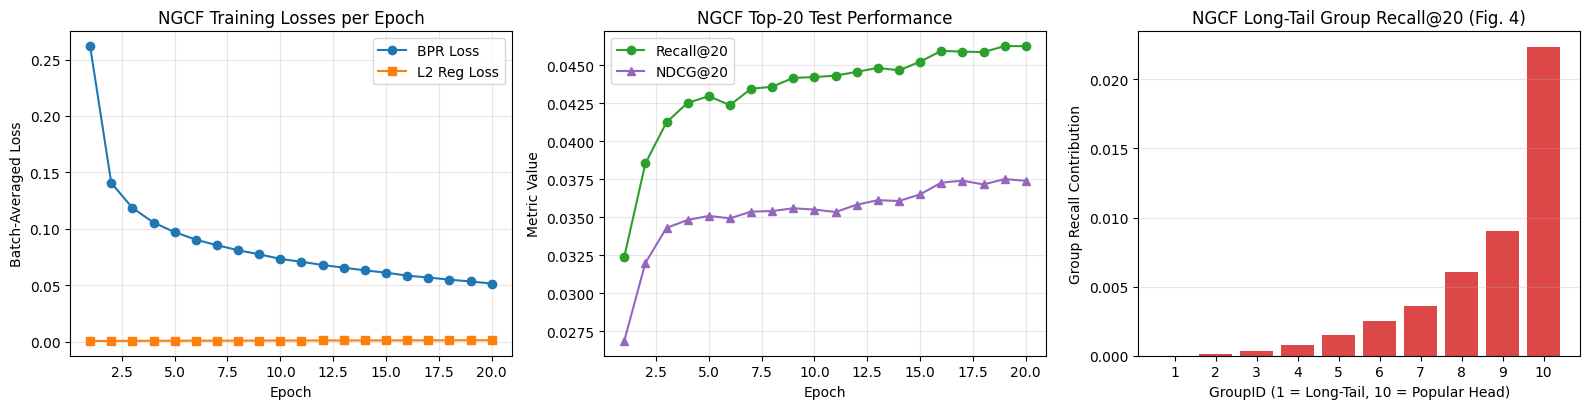

In [5]:
# ==============================================================================
# 5. Hyperparameter Configuration & End-to-End NGCF Training / Evaluation
# ==============================================================================

@dataclass
class NGCFConfig:
    # Dataset settings (use 'synthetic' for quick run, or 'yelp2018' / 'amazon-book' / 'ifashion')
    data_dir: str = "./dataset/yelp2018"
    dataset: str = "yelp2018"
    seed: int = 2021

    # NGCF Model Hyperparameters (matching SGL paper Section 4.1.1 & 4.1.2 + official NGCF repo)
    adj_type: str = "norm"          # 'norm': (D+I)^{-1}(A+I), 'ngcf': D^{-1}A+I, 'pre': D^{-1/2}AD^{-1/2}
    embed_size: int = 64            # Embedding dimension d (64 in SGL paper)
    layer_size: list[int] = field(default_factory=lambda: [64, 64, 64])  # 3 GCN layers
    reg: float = 1e-4               # L2 regularization coefficient lambda_2 (tuned in SGL paper)
    node_dropout_flag: int = 1      # 1: enable sparse Laplacian node dropout, 0: disable
    node_dropout: float = 0.1       # Sparse Laplacian dropout ratio (0.1 in NGCF)
    mess_dropout: list[float] = field(default_factory=lambda: [0.1, 0.1, 0.1])  # Message dropout per layer

    # Optimization & Evaluation settings (Section 4.1.2 of SGL paper)
    lr: float = 0.001               # Adam learning rate (0.001 in SGL paper)
    batch_size: int = 2048          # Mini-batch size (2048 in SGL paper)
    epochs: int = 30                # Number of training epochs (set to 400-1000 for full benchmarks)
    verbose: int = 1                # Evaluate every `verbose` epochs
    stop_cnt: int = 10              # Early stopping patience
    top_k: list[int] = field(default_factory=lambda: [20])
    test_batch_size: int = 128
    start_testing_epoch: int = 0


def run_ngcf_pipeline(cfg: NGCFConfig):
    """Runs the complete NGCF preprocessing, training, evaluation, and plotting pipeline."""
    set_seed(cfg.seed)

    print("=" * 80)
    print("NGCF: Neural Graph Collaborative Filtering (SIGIR '19 / SGL Baseline Setup)")
    print("=" * 80)
    print(
        f"[Config] dataset={cfg.dataset} | adj_type={cfg.adj_type} | "
        f"layers={cfg.layer_size} | embed_size={cfg.embed_size} | lr={cfg.lr} | "
        f"reg(lambda_2)={cfg.reg} | batch_size={cfg.batch_size}"
    )
    print(
        f"[Drop]   node_dropout_flag={cfg.node_dropout_flag} (rate={cfg.node_dropout}) | "
        f"mess_dropout={cfg.mess_dropout}"
    )
    print(f"[Device] Using {DEVICE}")

    # 1. Load dataset & construct normalized Laplacian matrix (Shared Preprocess Pipeline)
    dataset = SGLDataset(
        data_dir=cfg.data_dir,
        dataset_name=cfg.dataset,
        adj_type=cfg.adj_type,
        device=DEVICE,
    )
    print(
        f"[Data]   #Users: {dataset.num_users} | #Items: {dataset.num_items} | "
        f"#Train Interactions: {dataset.num_ratings}"
    )

    data_iter = PairwiseSampler(dataset, batch_size=cfg.batch_size, shuffle=True)
    evaluator = Evaluator(
        user_train_dict=dataset.train_user_dict,
        user_test_dict=dataset.test_user_dict,
        metrics=["Precision", "Recall", "NDCG"],
        top_k=cfg.top_k,
        batch_size=cfg.test_batch_size,
    )

    # 2. Initialize NGCF model (Xavier uniform init) & Adam Optimizer (lr=0.001)
    model = NGCF(
        n_users=dataset.num_users,
        n_items=dataset.num_items,
        norm_adj=dataset.norm_adj,
        emb_dim=cfg.embed_size,
        weight_size=cfg.layer_size,
        node_dropout_flag=cfg.node_dropout_flag,
        node_dropout=cfg.node_dropout,
        mess_dropout=cfg.mess_dropout,
        decay=cfg.reg,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)

    print("-" * 80)
    print("Metrics:\t" + evaluator.metrics_info())
    print("-" * 80)

    best_epoch = 0
    best_result = np.zeros(3 * len(cfg.top_k), dtype=np.float64)
    best_state_dict = None
    stopping_step = 0

    history = {"epoch": [], "bpr_loss": [], "reg_loss": [], "recall": [], "ndcg": []}

    # 3. Training & Evaluation Loop
    for epoch in range(1, cfg.epochs + 1):
        total_loss, total_bpr_loss, total_reg_loss = 0.0, 0.0, 0.0
        num_batches = 0
        t0 = time()

        model.train()
        for bat_users, bat_pos_items, bat_neg_items in data_iter:
            bat_users = torch.from_numpy(bat_users).long().to(DEVICE)
            bat_pos_items = torch.from_numpy(bat_pos_items).long().to(DEVICE)
            bat_neg_items = torch.from_numpy(bat_neg_items).long().to(DEVICE)

            u_g_emb, pos_i_g_emb, neg_i_g_emb = model(
                bat_users, bat_pos_items, bat_neg_items, drop_flag=bool(cfg.node_dropout_flag)
            )
            loss, mf_loss, emb_loss = model.create_bpr_loss(
                u_g_emb, pos_i_g_emb, neg_i_g_emb
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_bpr_loss += mf_loss.item()
            total_reg_loss += emb_loss.item()
            num_batches += 1

        avg_total = total_loss / max(1, num_batches)
        avg_bpr = total_bpr_loss / max(1, num_batches)
        avg_reg = total_reg_loss / max(1, num_batches)

        print(
            f"[iter {epoch:2d} : loss : {avg_total:.4f} = {avg_bpr:.4f} (BPR) + "
            f"{avg_reg:.4f} (Reg), time: {time() - t0:.2f}s]"
        )

        if epoch % cfg.verbose == 0 and epoch > cfg.start_testing_epoch:
            current_result, buf = evaluator.evaluate(model)
            print(f"epoch {epoch:2d}:\t{buf}")

            history["epoch"].append(epoch)
            history["bpr_loss"].append(avg_bpr)
            history["reg_loss"].append(avg_reg)
            history["recall"].append(current_result[1])
            history["ndcg"].append(current_result[2])

            if best_result[1] < current_result[1]:
                best_result = current_result
                best_epoch = epoch
                stopping_step = 0
                best_state_dict = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            else:
                stopping_step += 1
                if stopping_step >= cfg.stop_cnt:
                    print(f"Early stopping triggered at epoch: {epoch}")
                    break

    # 4. Restore best model & compute Long-Tail Group Recall (Section 4.3.1)
    if best_state_dict is not None:
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state_dict.items()})

    group_recalls = evaluator.evaluate_long_tail_groups(
        model=model,
        train_items=dataset.train_items,
        num_items=dataset.num_items,
        num_groups=10,
        k=cfg.top_k[0],
    )

    print("=" * 80)
    print(f"Best Result @ Epoch {best_epoch}:")
    print("Metrics:\t" + evaluator.metrics_info())
    print("Values: \t" + "\t".join([("%.8f" % x).ljust(12) for x in best_result]))
    print("-" * 80)
    group_str = " | ".join([f"G{g+1}: {val:.4f}" for g, val in enumerate(group_recalls)])
    print(f"Long-Tail Group Recall@{cfg.top_k[0]}: {group_str}")
    print("=" * 80)

    # 5. Plot Training Curves & Long-Tail Group Recall
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    axes[0].plot(history["epoch"], history["bpr_loss"], marker="o", label="BPR Loss")
    axes[0].plot(history["epoch"], history["reg_loss"], marker="s", label="L2 Reg Loss")
    axes[0].set_title("NGCF Training Losses per Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Batch-Averaged Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["epoch"], history["recall"], marker="o", color="tab:green", label=f"Recall@{cfg.top_k[0]}")
    axes[1].plot(history["epoch"], history["ndcg"], marker="^", color="tab:purple", label=f"NDCG@{cfg.top_k[0]}")
    axes[1].set_title(f"NGCF Top-{cfg.top_k[0]} Test Performance")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Metric Value")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].bar(np.arange(1, 11), group_recalls, color="tab:red", alpha=0.85)
    axes[2].set_title(f"NGCF Long-Tail Group Recall@{cfg.top_k[0]} (Fig. 4)")
    axes[2].set_xlabel("GroupID (1 = Long-Tail, 10 = Popular Head)")
    axes[2].set_ylabel("Group Recall Contribution")
    axes[2].set_xticks(np.arange(1, 11))
    axes[2].grid(True, axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, history, group_recalls


# Execute the NGCF pipeline with the SGL paper's experimental setup
config = NGCFConfig(
    embed_size=64,
    layer_size=[64, 64, 64],   # 3 GCN layers
    reg=1e-4,                  # Regularization coefficient lambda_2
    lr=0.001,                  # Adam learning rate in SGL paper (Section 4.1.2)
    batch_size=2048,           # Mini-batch size in SGL paper (Section 4.1.2)
    epochs=20,
)
trained_ngcf_model, ngcf_history, ngcf_long_tail_recalls = run_ngcf_pipeline(config)